# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [2]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

# complete

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3


In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [3]:
# Write your code here

S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = np.array([0.3, 0.7])
bias = 0.5

# 1. Compute linear combination z
z = S @ np.array(theta) + bias

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5)
probabilities = 1/(1+np.exp(-z))

# Identify predicted spam emails
predicted_spam = probabilities >= 0.5

print(z)
print(probabilities)
print(predicted_spam)

[6.3 1.8 4.7 2.2]
[0.99816706 0.85814894 0.9909867  0.90024951]
[ True  True  True  True]


In [ ]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities)
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [4]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [ ]:
# Auto graded cell (log)
# skip it

In [5]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"

# Write your code here
random_indices = rng.choice(n, 12, replace=False)
log.loc[random_indices, "failed_attempts"] = rng.integers(5, 11, 12)
print(log.loc[random_indices, ["user", "failed_attempts"]])

       user  failed_attempts
153    nour               10
250  yacine                6
86    karim                8
46      ali                9
227    nour                7
123     ali                8
283  yacine                9
269    nour               10
93   yacine                8
122   karim               10
7     karim                6
219    sara                9


In [ ]:
# Autograded cell (Failed attempts)
# Skip it

In [6]:
# Insert 10 missing values randomly

# Write your code here
log.loc[rng.choice(n, 10, replace=False), "duration_min"] = np.nan
print(log[log["duration_min"].isna()])

       user  hour  failed_attempts country  duration_min
13    karim     4                1      DZ           NaN
51     nour    12                1      DZ           NaN
64   yacine    17                1      RU           NaN
83    karim    15                0      TN           NaN
86    karim    22                8      DZ           NaN
92     nour    11                2      DZ           NaN
100     ali     3                0      DZ           NaN
164    nour     7                0      FR           NaN
194    sara    15                0      DZ           NaN
272    nour    21                0      DZ           NaN


In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [7]:
# Write your code here

ru_log_at_least_five_attempts = len(log[(log["failed_attempts"] >= 5) & (log["country"] == "RU")])
print("Russian logins with 5 or more failed attempts:", ru_log_at_least_five_attempts)

Russian logins with 5 or more failed attempts: 1


In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [22]:
# Write your code here

user_max_failed_attempts = log.groupby('user')['failed_attempts'].sum().sort_values(ascending=False).index[0]
print("User with the highest failed attempts is:", user_max_failed_attempts)

User with the highest failed attempts is: karim


In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [10]:
# Write your code here
log['long_session'] = 0
log.loc[log['duration_min'] > 30, 'long_session'] = 1
print(log[log['long_session'] == 1][['user', 'duration_min', 'long_session']])

       user  duration_min  long_session
16     nour          46.3             1
18      ali          33.8             1
32    karim          32.9             1
39     sara          37.2             1
57      ali          31.8             1
84     sara          31.1             1
108    sara          43.5             1
111     ali          35.0             1
114    nour          56.6             1
126    sara          30.6             1
130   karim          36.3             1
138   karim          30.8             1
148  yacine          35.5             1
155   karim          34.2             1
158  yacine          48.4             1
166   karim          34.9             1
169   karim          30.8             1
178    nour          39.0             1
181    nour          54.6             1
228     ali          50.5             1
246  yacine          33.7             1
251    sara          50.6             1
252     ali          32.7             1
254     ali          48.1             1


In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

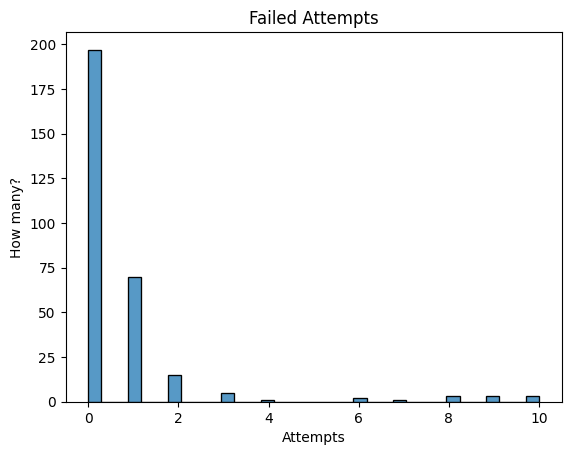

In [11]:
# Draw the histogram of failed_attempts.
# Write your code here

sns.histplot(log['failed_attempts'])
plt.title("Failed Attempts")
plt.xlabel("Attempts")
plt.ylabel("How many?")
plt.show()

In [ ]:
# Auto-graded cell - Skip it...

In [ ]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

In [ ]:
# Write your code here
answer_q2 = "B"

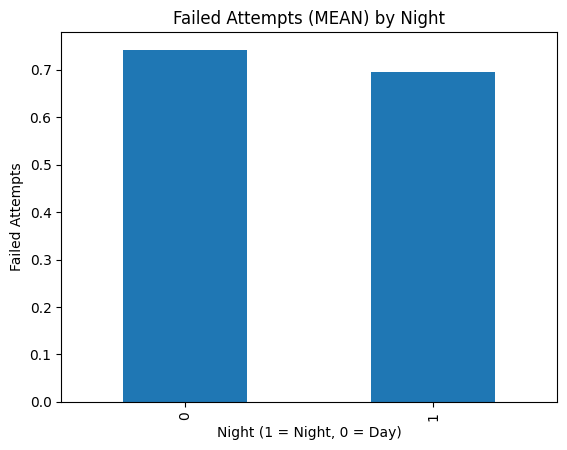

In [12]:
# 3. Draw a bar chart of the mean failed_attempts per night value.

# Write your code here

log['night'] = 0
log.loc[(log['hour'] < 6), 'night'] = 1

mean_per_night = log.groupby('night')['failed_attempts'].mean()
mean_per_night.plot(kind='bar')

plt.title("Failed Attempts (MEAN) by Night")
plt.xlabel("Night (1 = Night, 0 = Day)")
plt.ylabel("Failed Attempts")
plt.show()

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
# Write your code here
# Please write a sentence response instead of code
a 1 dimension NumPy array containing all elements from the 3rd column from all 300 rows

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [13]:
# Write your code here
log.isnull().sum()

,0
user,0
hour,0
failed_attempts,0
country,0
duration_min,10
long_session,0
night,0


Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

I would use a bar chart or a box plot to compare them.


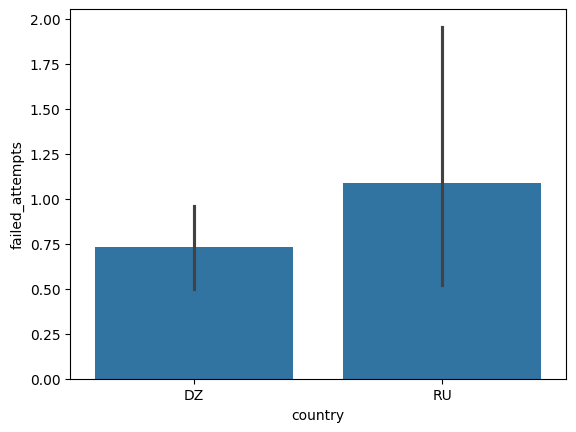

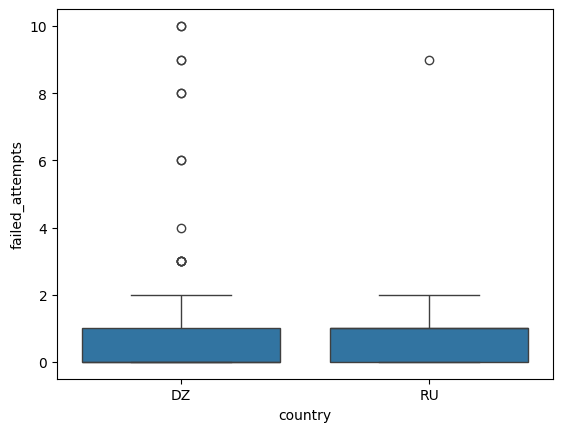

In [18]:
# Write your code here
print("I would use a bar chart or a box plot to compare them.")

sns.barplot(x='country', y='failed_attempts', data=log[(log['country'] == 'DZ') | (log['country'] == 'RU')])
plt.show()

sns.boxplot(x='country', y='failed_attempts', data=log[(log['country'] == 'DZ') | (log['country'] == 'RU')])
plt.show()

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [21]:
# Write your code here
Scaling puts every feature on the same scale so that no feature dominates the others, meaning they all have the same importance.

Scaling puts every feature on the same scale so that no feature dominates the others, meaning they all have the same importance.


Commit the logins_clean.csv.(0.5 point)

In [ ]:
# save the cleaned table in login_clean.csv
# Write your code here

In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [ ]:
# Write your code here

In [ ]:
import numpy as np
import pandas as pd
